# Parte V. Grafos y detección de comunidades

**Integrantes:** Ricardo Acuña, Juan Aquino y Camilo Soto.

**Pregunta que responde.** ¿Hay grupos de proveedores que compiten siempre entre sí, y qué son esos grupos: regiones, rubros o algo que no está en ninguna etiqueta? Es la segunda mitad de la pregunta 3 del proyecto. Una comunidad en el grafo de coparticipación es un conjunto de proveedores que se encuentran en los mismos procesos mucho más que con el resto: un **mercado de competencia**. Saber cuáles son sirve para dos cosas. Para medir la competencia donde realmente ocurre, y no por departamento o por rubro a ciegas. Y para ubicar las señales de las partes anteriores, como los pares que alternan victorias, dentro del mercado en que viven.

**El grafo.** El de coparticipación de la Parte I: proveedores unidos si compitieron en al menos 2 procesos de hasta 50 participantes, con peso de Newman 1 / (n menos 1).

**Tres métricas, con preguntas distintas.**

1. **Modularidad Q.** ¿Las comunidades tienen más peso de aristas por dentro del que tendrían al azar con los mismos grados? Va de menos 0,5 a 1; por encima de 0,3 suele haber estructura real. No necesita etiquetas, y por eso sirve para elegir cuántas comunidades cortar.
2. **ARI, índice de Rand ajustado.** De todos los pares de proveedores, ¿en cuántos coinciden dos particiones, juntos en ambas o separados en ambas, descontando el acuerdo que habría por azar? 0 es azar y 1 es identidad.
3. **NMI, información mutua normalizada.** Si conozco la comunidad de un proveedor, ¿cuánto sé de su grupo en la otra partición? 0 es nada y 1 es todo. Es más tolerante que ARI cuando una partición divide en dos un grupo de la otra.

Q dice si hay mercados cerrados; ARI y NMI dicen si dos métodos encontraron los mismos mercados, y si esos mercados son el departamento, el rubro o los perfiles de la Parte II.

**Dónde corre.** La propagación de etiquetas sobre el grafo nacional corre en Spark. Girvan-Newman, espectral, Louvain y BigCLAM corren en local sobre subgrafos, y la sección 2 mide por qué.

In [1]:
import sys, time, pickle
from pathlib import Path

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ / "notebooks" / "scripts"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx
from pyspark.sql import Window
from pyspark.sql import functions as F
from scipy import sparse
from scipy.sparse.csgraph import connected_components

from helpers import (PARQUET, BASE, FIGS, ARTEFACTOS, FIGURAS, HALLAZGOS, PALETA,
                     AZUL, ROJO, VERDE, MORADO, TEAL, TINTA, SUAVE, REJILLA, fmt, MILES,
                     abrir_spark, cronometro, figura, exportar, hallazgo, barras_h, mapa_calor)
from comunidades import (modularidad, girvan_newman, espectral, propagacion_etiquetas_spark,
                         bigclam, membresias_bigclam, ari, nmi, verificar)

pd.set_option("display.width", 190)
pd.set_option("display.max_colwidth", 64)

# Los pasos caros se guardan en data/processed/parte5 y se reutilizan si existen.
RECALCULAR = False
CACHE = BASE / "parte5"
CACHE.mkdir(exist_ok=True)
def guardado(nombre, calcular):
    ruta = CACHE / f"{nombre}.pkl"
    if RECALCULAR or not ruta.exists():
        with open(ruta, "wb") as f:
            pickle.dump(calcular(), f)
    with open(ruta, "rb") as f:
        return pickle.load(f)

print("pruebas con el club de karate (Q, Brandes, Girvan-Newman, ARI y NMI):", verificar())
spark = abrir_spark("P2-V-Comunidades", memoria="2g")
aristas_sp = spark.read.parquet(str(BASE / "grafo_aristas"))
ar = aristas_sp.toPandas()
nod = spark.read.parquet(str(BASE / "grafo_nodos")).toPandas()
clusters = spark.read.parquet(str(BASE / "clusters_proveedores")).toPandas()
perfiles = pd.read_csv(ARTEFACTOS / "p2_perfiles.csv")[["cluster", "perfil"]]
pares = pd.read_parquet(BASE / "parte4" / "pares_afines.parquet")
item_tipico = pd.read_parquet(BASE / "parte4" / "nombre_familia.parquet").item_tipico

pruebas con el club de karate (Q, Brandes, Girvan-Newman, ARI y NMI): True


Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).


26/11/17 21:33:30 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


## 1. Dónde vive cada proveedor

Para leer una comunidad hace falta saber qué es cada proveedor. Se le asigna el departamento y la familia CUBSO más frecuentes de los procesos en que participó; el cálculo es un join de 2,2 millones de participaciones con la tabla de procesos y corre en Spark. Con eso se mide cuánto del grafo es regional: qué parte del peso de las aristas une a proveedores del mismo departamento.

In [2]:
def ubicar():
    tabla = spark.read.parquet(str(PARQUET)).select("ocid", "departamento")
    fam = spark.read.parquet(str(BASE / "hechos")).select("ocid", "familia").dropna().dropDuplicates(["ocid"])
    part = spark.read.parquet(str(BASE / "participaciones")).select("ocid", "nodo").dropDuplicates()
    p = part.join(tabla, "ocid", "left").join(fam, "ocid", "left").cache()
    def moda(col):
        c = p.dropna(subset=[col]).groupBy("nodo", col).agg(F.count("*").alias("c"))
        w = Window.partitionBy("nodo").orderBy(F.desc("c"), F.asc(col))
        tot = c.groupBy("nodo").agg(F.sum("c").alias("t"))
        return (c.withColumn("r", F.row_number().over(w)).filter("r = 1").join(tot, "nodo")
                 .select("nodo", col, (F.col("c") / F.col("t")).alias(f"pct_{col}")))
    return moda("departamento").join(moda("familia"), "nodo", "outer").toPandas()

with cronometro("ubicación de cada proveedor en Spark"):
    ubic = guardado("ubicacion", ubicar)
nod = nod.merge(ubic, on="nodo", how="left").merge(clusters[["nodo", "cluster"]].merge(perfiles, on="cluster"),
                                                   on="nodo", how="left")
nod["item_tipico"] = nod.familia.map(item_tipico).fillna("sin familia")
depto = nod.set_index("nodo").departamento
mismo = ar.src.map(depto).values == ar.dst.map(depto).values
pct_peso_mismo = 100 * ar.peso[mismo].sum() / ar.peso.sum()
print(f"El {pct_peso_mismo:.0f} % del peso de las aristas une proveedores del mismo departamento "
      f"({100*mismo.mean():.0f} % de las aristas). Mediana de la concentración del proveedor en su departamento: "
      f"{100*nod.pct_departamento.median():.0f} %")

idx_g1 = pd.Index(nod.nodo.values)
def matriz(a, idx):
    s, d = idx.get_indexer(a.src), idx.get_indexer(a.dst)
    ok = (s >= 0) & (d >= 0)
    s, d, w = s[ok], d[ok], a.peso.values[ok]
    return sparse.csr_matrix((np.r_[w, w], (np.r_[s, d], np.r_[d, s])), shape=(len(idx), len(idx)))
A_g1 = matriz(ar, idx_g1)

ubicación de cada proveedor en Spark: 22.42 s


El 60 % del peso de las aristas une proveedores del mismo departamento (51 % de las aristas). Mediana de la concentración del proveedor en su departamento: 95 %


## 2. Por qué los métodos exactos exigen un subgrafo

Girvan-Newman recalcula la intermediación de todas las aristas después de cada corte. La intermediación con el algoritmo de Brandes cuesta del orden de n por m, y hay que repetirla m veces, así que el total crece como n por m al cuadrado. Antes de elegir el subgrafo se mide: Girvan-Newman sobre los n proveedores más conectados de un departamento, para n creciente, y se ajusta la pendiente en escala logarítmica para extrapolar al grafo nacional.

El subgrafo de prueba es **Ayacucho**: un mercado regional mediano, con unos mil proveedores que compitieron al menos 5 veces entre sí. Es lo bastante grande para tener estructura y lo bastante chico para que los métodos exactos y BigCLAM terminen.

In [3]:
MIN_PROCESOS = 5
def subgrafo(dep):
    nn = set(nod.nodo[nod.departamento == dep])
    s = ar[ar.src.isin(nn) & ar.dst.isin(nn) & (ar.procesos >= MIN_PROCESOS)]
    idx = pd.Index(np.union1d(s.src, s.dst))
    A = matriz(s, idx)
    _, comp = connected_components(A)
    g = comp == np.bincount(comp).argmax()
    return A[g][:, g].tocsr(), idx[g]

A_ay, idx_ay = subgrafo("AYACUCHO")
fuerza_ay = np.asarray(A_ay.sum(1)).ravel()
print(f"Ayacucho: {A_ay.shape[0]:,} proveedores y {A_ay.nnz // 2:,} aristas en la componente gigante")

def top_n(n):
    k = np.sort(np.argsort(-fuerza_ay)[:n])
    B = A_ay[k][:, k]
    _, comp = connected_components(B)
    g = comp == np.bincount(comp).argmax()
    return B[g][:, g].tocsr(), k[g]

def medir_gn():
    filas = []
    for n in [40, 70, 100, 130]:
        B, _ = top_n(n)
        t0 = time.perf_counter(); girvan_newman(B); t = time.perf_counter() - t0
        filas.append({"metodo": "Girvan-Newman", "nodos": B.shape[0], "aristas": B.nnz // 2, "segundos": t})
    return pd.DataFrame(filas)
escala = guardado("escalabilidad_gn", medir_gn)
pend = np.polyfit(np.log(escala.nodos), np.log(escala.segundos), 1)
print(escala.round(2).to_string(index=False))
print(f"El tiempo de Girvan-Newman crece como n elevado a {pend[0]:.1f}")

Ayacucho: 1,065 proveedores y 9,650 aristas en la componente gigante


       metodo  nodos  aristas  segundos
Girvan-Newman     37      348      1.62
Girvan-Newman     67      941     19.22
Girvan-Newman     96     1617    106.44
Girvan-Newman    123     2203    194.60
El tiempo de Girvan-Newman crece como n elevado a 4.1


## 3. Girvan-Newman sobre el núcleo de Ayacucho

Se toman los 150 proveedores con más peso de aristas en Ayacucho, el núcleo de su mercado. El algoritmo corta en cada paso la arista con mayor intermediación, la que más caminos más cortos atraviesan: es un puente entre grupos. Cada vez que el grafo se parte en más componentes se registra la partición y su Q. La intermediación se calcula sin pesos, porque aquí el peso es una similitud y no una distancia; la modularidad sí usa los pesos.

**Cuántas comunidades.** La regla habitual es el máximo de Q, pero la curva de Q suele ser plana cerca del máximo y el máximo cae en una partición muy fina. Se elige el **codo**: el punto de la curva, entre el inicio y el máximo, más alejado de la recta que los une. Es la partición a partir de la cual cortar más casi no mejora Q.

Girvan-Newman sobre el núcleo: 376.95 s
Núcleo: 143 proveedores, 2,798 aristas. Codo en k = 5 (Q = 0.361); máximo en k = 24 (Q = 0.366)



Lectura de f27_girvan_newman_q
Al cortar las aristas puente, la modularidad sube rápido hasta unas 5 comunidades (Q = 0.36) y después se aplana: el máximo, Q = 0.37, llega recién con 24 comunidades, muchas de ellas de uno o dos proveedores. Se adopta el codo. Un Q por encima de 0,3 dice que el núcleo del mercado de Ayacucho no es un solo bloque donde todos compiten con todos, sino varios grupos que se encuentran entre sí mucho más que con el resto.



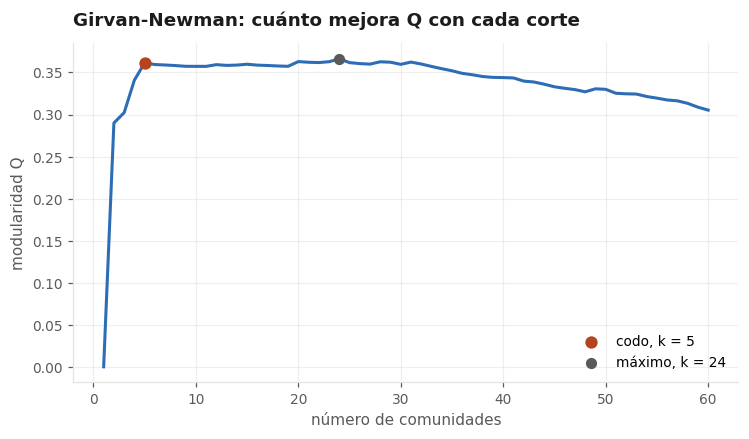

In [4]:
def codo(x, y):
    """Índice del punto más alejado de la cuerda entre el primero y el máximo."""
    x, y = np.asarray(x, float), np.asarray(y, float)
    i_max = int(np.argmax(y))
    if i_max == 0:
        return 0
    xs = (x[:i_max + 1] - x[0]) / (x[i_max] - x[0])
    ys = (y[:i_max + 1] - y[0]) / (y[i_max] - y[0])
    return int(np.argmax(ys - xs))

A_gn, sel_gn = top_n(150)
with cronometro("Girvan-Newman sobre el núcleo"):
    hist_gn = guardado("girvan_newman_150", lambda: girvan_newman(A_gn))
curva_gn = pd.DataFrame([{"k": h["k"], "Q": h["Q"], "cortes": h["cortes"]} for h in hist_gn])
curva_gn = curva_gn[curva_gn.k <= 60]
i_codo = codo(curva_gn.k, curva_gn.Q)
k_gn, q_gn = int(curva_gn.k.iloc[i_codo]), float(curva_gn.Q.iloc[i_codo])
k_max, q_max = int(curva_gn.k.iloc[curva_gn.Q.argmax()]), float(curva_gn.Q.max())
etq_gn = next(h["etiquetas"] for h in hist_gn if h["k"] == k_gn)
print(f"Núcleo: {A_gn.shape[0]} proveedores, {A_gn.nnz // 2:,} aristas. Codo en k = {k_gn} (Q = {q_gn:.3f}); "
      f"máximo en k = {k_max} (Q = {q_max:.3f})")
exportar(curva_gn.round(4), "p5_gn_curva", "Modularidad de cada particion de Girvan-Newman sobre el nucleo de Ayacucho")

fig, ax = plt.subplots(figsize=(7.8, 4))
ax.plot(curva_gn.k, curva_gn.Q, color=AZUL, lw=2)
ax.scatter([k_gn], [q_gn], color=ROJO, zorder=3, s=50, label=f"codo, k = {k_gn}")
ax.scatter([k_max], [q_max], color=SUAVE, zorder=3, s=40, label=f"máximo, k = {k_max}")
ax.set_xlabel("número de comunidades"); ax.set_ylabel("modularidad Q")
ax.set_title("Girvan-Newman: cuánto mejora Q con cada corte", loc="left", pad=12)
ax.legend(); ax.grid(alpha=.6)
figura(fig, "f27_girvan_newman_q", f"""
Al cortar las aristas puente, la modularidad sube rápido hasta unas {k_gn} comunidades (Q = {q_gn:.2f}) y
después se aplana: el máximo, Q = {q_max:.2f}, llega recién con {k_max} comunidades, muchas de ellas de uno o dos
proveedores. Se adopta el codo. Un Q por encima de 0,3 dice que el núcleo del mercado de Ayacucho no es un
solo bloque donde todos compiten con todos, sino varios grupos que se encuentran entre sí mucho más que
con el resto.""")

## 4. Espectral y Louvain sobre Ayacucho completo

**Espectral.** Se toman los k vectores propios mayores de la adyacencia normalizada D a la menos un medio por A por D a la menos un medio, que son los menores del laplaciano normalizado, se normaliza cada fila y se agrupan las filas con KMeans (Ng, Jordan y Weiss). Cada vector propio es una forma suave de partir el grafo, y KMeans las combina. Se barre k y se elige por el codo de Q, como en Girvan-Newman.

**Louvain.** No está en el enunciado como método exigido, pero es la referencia escalable que optimiza Q directamente, moviendo nodos entre comunidades y fusionando. Sirve de techo práctico: dice cuánta modularidad hay disponible en este grafo.

espectral para k de 2 a 25: 8.73 s


Espectral: codo en k = 6, Q = 0.401. Louvain: 20 comunidades, Q = 0.644 en 0.24 s



Lectura de f28_espectral_q
El espectral sobre los 1,065 proveedores de Ayacucho tiene su codo en k = 6, con Q = 0.40. Louvain, que optimiza la modularidad de forma directa, llega a Q = 0.64 con 20 comunidades en 0.24 segundos. La distancia entre las dos curvas es lo que cuesta pedirle al espectral que use pocos grupos; la conclusión de negocio es la misma con ambos: el mercado regional está fragmentado en submercados que casi no se tocan.



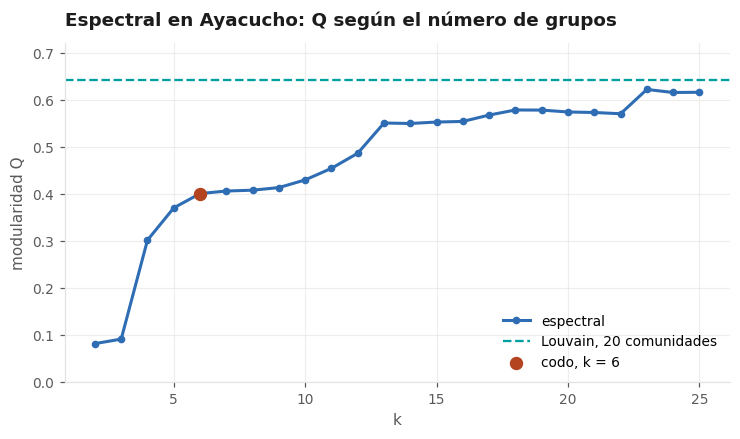

In [5]:
def barrer_espectral():
    filas = []
    for k in range(2, 26):
        e, _ = espectral(A_ay, k)
        filas.append({"k": k, "Q": modularidad(A_ay, e), "etiquetas": e})
    return filas
with cronometro("espectral para k de 2 a 25"):
    esp = guardado("espectral_ayacucho", barrer_espectral)
curva_esp = pd.DataFrame([{"k": f["k"], "Q": f["Q"]} for f in esp])
i_e = codo(curva_esp.k, curva_esp.Q)
k_esp = int(curva_esp.k.iloc[i_e]); q_esp = float(curva_esp.Q.iloc[i_e])
etq_esp = esp[i_e]["etiquetas"]
t0 = time.perf_counter()
G_ay = nx.from_scipy_sparse_array(A_ay)
louv = nx.community.louvain_communities(G_ay, weight="weight", seed=0)
t_louv = time.perf_counter() - t0
etq_louv = np.empty(A_ay.shape[0], int)
for c, miembros in enumerate(louv):
    etq_louv[list(miembros)] = c
q_louv = modularidad(A_ay, etq_louv)
print(f"Espectral: codo en k = {k_esp}, Q = {q_esp:.3f}. Louvain: {len(louv)} comunidades, Q = {q_louv:.3f} en {t_louv:.2f} s")
exportar(curva_esp.round(4), "p5_espectral_curva", "Modularidad del espectral segun k sobre Ayacucho")

fig, ax = plt.subplots(figsize=(7.8, 4))
ax.plot(curva_esp.k, curva_esp.Q, "o-", color=AZUL, lw=2, ms=4, label="espectral")
ax.axhline(q_louv, color=TEAL, ls="--", lw=1.5, label=f"Louvain, {len(louv)} comunidades")
ax.scatter([k_esp], [q_esp], color=ROJO, s=60, zorder=3, label=f"codo, k = {k_esp}")
ax.set_xlabel("k"); ax.set_ylabel("modularidad Q"); ax.set_ylim(0, max(q_louv, curva_esp.Q.max()) * 1.12)
ax.set_title("Espectral en Ayacucho: Q según el número de grupos", loc="left", pad=12)
ax.legend(loc="lower right"); ax.grid(alpha=.6)
figura(fig, "f28_espectral_q", f"""
El espectral sobre los {A_ay.shape[0]:,} proveedores de Ayacucho tiene su codo en k = {k_esp}, con Q = {q_esp:.2f}.
Louvain, que optimiza la modularidad de forma directa, llega a Q = {q_louv:.2f} con {len(louv)} comunidades en
{t_louv:.2f} segundos. La distancia entre las dos curvas es lo que cuesta pedirle al espectral que use pocos
grupos; la conclusión de negocio es la misma con ambos: el mercado regional está fragmentado en
submercados que casi no se tocan.""")

## 5. ¿Encontraron lo mismo? ARI y NMI entre métodos y contra etiquetas

Una Q alta no garantiza que las comunidades sean las mismas con otro método, ni que signifiquen algo. Se comparan:

1. **Métodos entre sí** sobre los 150 proveedores del núcleo, donde corrieron los tres.
2. **Comunidades contra etiquetas de negocio** en Ayacucho: la familia CUBSO principal del proveedor y su tipo (empresa, persona natural, consorcio).
3. **Comunidades contra los perfiles de la Parte II**, para los proveedores recurrentes que tienen perfil.

Si las comunidades coinciden con la familia, el mercado de competencia es el rubro. Si no coinciden con nada, son una estructura nueva que ninguna etiqueta dice.

                             comparacion  proveedores   ARI   NMI
Girvan-Newman frente a espectral, núcleo          143 0.890 0.908
  Girvan-Newman frente a Louvain, núcleo          143 0.421 0.647
    espectral frente a Louvain, Ayacucho         1065 0.152 0.474
        espectral frente a familia CUBSO         1060 0.277 0.386
          Louvain frente a familia CUBSO         1060 0.220 0.506
      Louvain frente a tipo de proveedor         1065 0.004 0.020
  Louvain frente a perfil de la Parte II          296 0.010 0.112



Lectura de f29_acuerdo_particiones
En el núcleo, Girvan-Newman y el espectral encuentran casi la misma partición (NMI de 0.91, ARI de 0.89), por caminos completamente distintos: cortar puentes y factorizar la matriz. Louvain coincide menos (NMI de 0.65) porque parte los mismos bloques en más comunidades. Las comunidades se parecen al rubro, con NMI de 0.51 contra la familia CUBSO, y casi nada al tipo de proveedor (0.02) o al perfil de la Parte II (0.11). El ARI es siempre menor que el NMI porque castiga que un método divida en dos lo que otro deja junto. Lectura de negocio: dentro de una región, el mercado de competencia se parece al rubro pero no es el rubro, y no dice nada de cómo se comporta cada proveedor.



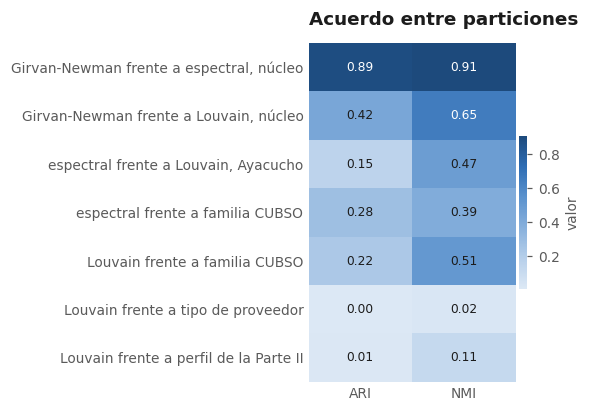

In [6]:
pos_gn = sel_gn                                   # posición en A_ay de cada nodo del núcleo
filas = [
    ("Girvan-Newman frente a espectral, núcleo", etq_gn, etq_esp[pos_gn]),
    ("Girvan-Newman frente a Louvain, núcleo", etq_gn, etq_louv[pos_gn]),
    ("espectral frente a Louvain, Ayacucho", etq_esp, etq_louv)]
info_ay = nod.set_index("nodo").reindex(idx_ay)
con_fam = info_ay.familia.notna().values
filas += [("espectral frente a familia CUBSO", etq_esp[con_fam], info_ay.familia.values[con_fam]),
          ("Louvain frente a familia CUBSO", etq_louv[con_fam], info_ay.familia.values[con_fam]),
          ("Louvain frente a tipo de proveedor", etq_louv, info_ay.tipo.values)]
con_perfil = info_ay.perfil.notna().values
filas += [("Louvain frente a perfil de la Parte II", etq_louv[con_perfil], info_ay.perfil.values[con_perfil])]
acuerdo = pd.DataFrame([{"comparacion": n, "proveedores": len(a), "ARI": ari(a, b), "NMI": nmi(a, b)} for n, a, b in filas])
print(acuerdo.round(3).to_string(index=False))
exportar(acuerdo.round(4), "p5_acuerdo", "ARI y NMI entre metodos y contra etiquetas de negocio")
fig, ax = mapa_calor(acuerdo.set_index("comparacion")[["ARI", "NMI"]], "Acuerdo entre particiones", "valor", "{:.2f}")
a = acuerdo.set_index("comparacion")
figura(fig, "f29_acuerdo_particiones", f"""
En el núcleo, Girvan-Newman y el espectral encuentran casi la misma partición (NMI de
{a.loc['Girvan-Newman frente a espectral, núcleo','NMI']:.2f}, ARI de {a.loc['Girvan-Newman frente a espectral, núcleo','ARI']:.2f}),
por caminos completamente distintos: cortar puentes y factorizar la matriz. Louvain coincide menos (NMI de
{a.loc['Girvan-Newman frente a Louvain, núcleo','NMI']:.2f}) porque parte los mismos bloques en más comunidades. Las comunidades se parecen al rubro, con NMI de
{a.loc['Louvain frente a familia CUBSO','NMI']:.2f} contra la familia CUBSO, y casi nada al tipo de proveedor
({a.loc['Louvain frente a tipo de proveedor','NMI']:.2f}) o al perfil de la Parte II
({a.loc['Louvain frente a perfil de la Parte II','NMI']:.2f}). El ARI es siempre menor que el NMI porque castiga
que un método divida en dos lo que otro deja junto. Lectura de negocio: dentro de una región, el mercado de
competencia se parece al rubro pero no es el rubro, y no dice nada de cómo se comporta cada proveedor.""")

## 6. La variante escalable: propagación de etiquetas en Spark sobre el grafo nacional

Girvan-Newman no puede correr sobre 70 mil nodos y 2,5 millones de aristas. La propagación de etiquetas sí: cada nodo empieza con su propia etiqueta y en cada ronda adopta la que más peso suma entre sus vecinos. Cada ronda es un join y un groupBy, que es exactamente el tipo de operación que Spark reparte. Es lo que ofrece GraphFrames; aquí está escrito sobre DataFrames. No optimiza Q de forma explícita, así que su Q se mide después.

Como referencia de calidad se corre también **Louvain sobre el grafo nacional**, en una sola máquina. Cabe en memoria a este tamaño, y su modularidad dice cuánta estructura deja sin capturar la variante escalable.

propagación de etiquetas en Spark: 70.97 s


Louvain sobre el grafo nacional: 65.28 s


Louvain nacional: 812 comunidades, Q = 0.656; acuerdo con la propagación de etiquetas: NMI 0.68, ARI 0.50
15 rondas en 71 s; cambios por ronda: [70383, 56240, 30039, 16368, 11196, 8716, 8100, 6553, 5804, 5871, 5439, 4920, 4480, 4490, 4333]
2,865 comunidades; la mayor tiene 21,292 proveedores; Q = 0.208


                                comparacion   ARI   NMI
 propagación nacional frente a departamento 0.028 0.191
propagación nacional frente a familia CUBSO 0.255 0.496
     Louvain nacional frente a departamento 0.016 0.136
    Louvain nacional frente a familia CUBSO 0.313 0.478
     propagación frente a Louvain, nacional 0.504 0.676
           comunidad  proveedores departamento  pct_departamento familia                                        item_tipico  pct_familia  pct_personas_naturales  monto_ganado
 -340900058973003127        21292         LIMA                37    7212 SERVICIO DE MANTENIMIENTO DE INFRAESTRUCTURA DE CE           20                      18  1.456647e+10
-1648568617511472310        16482         LIMA                15    7214     SERVICIO DE MANTENIMIENTO RUTINARIO DE CAMINOS           64                       4  2.306383e+10
 5710896837360462443         8027         LIMA                19    8110 SUPERVISION DE OBRA DE CONSTRUCCION DE CALLES Y SI           72   


Lectura de f30_comunidades_nacionales
Cada competencia es local, porque el 60 por ciento del peso de las aristas une a proveedores del mismo departamento, pero los mercados se encadenan a escala nacional por rubro. La propagación de etiquetas en Spark encuentra 2,865 comunidades, y las más grandes son mercados nacionales de servicios, como el mantenimiento de caminos o la supervisión de obra, con Lima como el departamento más frecuente pero minoritario; las de bienes pesados, como el cemento, sí son regionales. Las métricas lo confirman: NMI de 0.50 contra la familia y de solo 0.19 contra el departamento, y Louvain, la referencia de una sola máquina, dice lo mismo (0.48 frente a 0.14). La variante escalable reencuentra la estructura de Louvain (NMI 0.68) pero con menos calidad, Q de 0.21 frente a 0.66, porque tiende a fusionar mercados vecinos en una comunidad gigante.



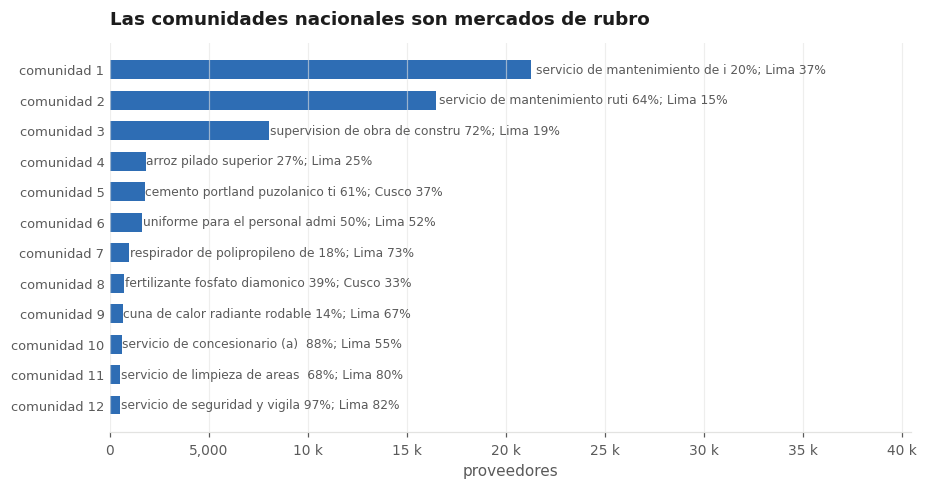

In [7]:
def correr_lpa():
    nodos_sp = spark.createDataFrame(nod[["nodo"]])
    t0 = time.perf_counter()
    etq, cambios = propagacion_etiquetas_spark(aristas_sp, nodos_sp, max_iter=15)
    etq = etq.toPandas()
    return {"etiquetas": etq, "cambios": cambios, "segundos": time.perf_counter() - t0}
with cronometro("propagación de etiquetas en Spark"):
    lpa = guardado("lpa_nacional", correr_lpa)
etq_lpa = lpa["etiquetas"].set_index("nodo").etiqueta.reindex(idx_g1).values
q_lpa = modularidad(A_g1, etq_lpa)

def correr_louvain_nacional():
    t0 = time.perf_counter()
    T = sparse.triu(A_g1, 1).tocoo()
    G = nx.Graph(); G.add_nodes_from(range(A_g1.shape[0]))
    G.add_weighted_edges_from(zip(T.row.tolist(), T.col.tolist(), T.data.tolist()))
    L = nx.community.louvain_communities(G, weight="weight", seed=0)
    e = np.empty(A_g1.shape[0], int)
    for c, m in enumerate(L):
        e[list(m)] = c
    # Indexado por nodo y no por posición: Spark no garantiza el orden de las filas entre lecturas.
    return {"etiquetas": pd.Series(e, index=idx_g1), "segundos": time.perf_counter() - t0}
with cronometro("Louvain sobre el grafo nacional"):
    lv_nac = guardado("louvain_nacional", correr_louvain_nacional)
etq_lvn = lv_nac["etiquetas"].reindex(idx_g1).values
q_lvn = modularidad(A_g1, etq_lvn)
print(f"Louvain nacional: {len(np.unique(etq_lvn)):,} comunidades, Q = {q_lvn:.3f}; "
      f"acuerdo con la propagación de etiquetas: NMI {nmi(etq_lvn, etq_lpa):.2f}, ARI {ari(etq_lvn, etq_lpa):.2f}")
tam = pd.Series(etq_lpa).value_counts()
print(f"{len(lpa['cambios'])} rondas en {lpa['segundos']:.0f} s; cambios por ronda: {lpa['cambios']}")
print(f"{len(tam):,} comunidades; la mayor tiene {tam.iloc[0]:,} proveedores; Q = {q_lpa:.3f}")

nod["comunidad"] = etq_lpa
con_dep = nod.departamento.notna() & nod.familia.notna()
nod["comunidad_louvain"] = etq_lvn
nac = pd.DataFrame([
    {"comparacion": "propagación nacional frente a departamento", "ARI": ari(nod.comunidad[con_dep], nod.departamento[con_dep]),
     "NMI": nmi(nod.comunidad[con_dep], nod.departamento[con_dep])},
    {"comparacion": "propagación nacional frente a familia CUBSO", "ARI": ari(nod.comunidad[con_dep], nod.familia[con_dep]),
     "NMI": nmi(nod.comunidad[con_dep], nod.familia[con_dep])},
    {"comparacion": "Louvain nacional frente a departamento", "ARI": ari(nod.comunidad_louvain[con_dep], nod.departamento[con_dep]),
     "NMI": nmi(nod.comunidad_louvain[con_dep], nod.departamento[con_dep])},
    {"comparacion": "Louvain nacional frente a familia CUBSO", "ARI": ari(nod.comunidad_louvain[con_dep], nod.familia[con_dep]),
     "NMI": nmi(nod.comunidad_louvain[con_dep], nod.familia[con_dep])},
    {"comparacion": "propagación frente a Louvain, nacional", "ARI": ari(etq_lpa, etq_lvn), "NMI": nmi(etq_lpa, etq_lvn)}])
print(nac.round(3).to_string(index=False))
acuerdo = pd.concat([acuerdo, nac.assign(proveedores=int(con_dep.sum()))], ignore_index=True)
nd = nac.set_index("comparacion")
exportar(acuerdo.round(4), "p5_acuerdo", "ARI y NMI entre metodos y contra etiquetas de negocio")

grandes = tam.index[:12]
perfil_c = []
for c in grandes:
    m = nod[nod.comunidad == c]
    dep = m.departamento.value_counts(normalize=True); fam = m.familia.value_counts(normalize=True)
    perfil_c.append({"comunidad": int(c), "proveedores": len(m), "departamento": dep.index[0] if len(dep) else "",
                     "pct_departamento": round(100 * dep.iloc[0]) if len(dep) else 0,
                     "familia": fam.index[0] if len(fam) else "", "item_tipico": str(item_tipico.get(fam.index[0], ""))[:50] if len(fam) else "",
                     "pct_familia": round(100 * fam.iloc[0]) if len(fam) else 0,
                     "pct_personas_naturales": round(100 * (m.tipo == "persona natural").mean()),
                     "monto_ganado": m.monto_total.sum()})
perfil_c = pd.DataFrame(perfil_c)
print(perfil_c.to_string(index=False))
exportar(perfil_c, "p5_comunidades_nacionales", "Las 12 comunidades nacionales mas grandes y su perfil")

fig, ax = plt.subplots(figsize=(9.4, 4.6))
y = np.arange(len(perfil_c))[::-1]
ax.barh(y, perfil_c.proveedores, color=AZUL, height=.62)
for yi, r in zip(y, perfil_c.itertuples()):
    ax.text(r.proveedores * 1.01, yi, f"{r.item_tipico[:30].lower()} {r.pct_familia}%; {r.departamento.title()} {r.pct_departamento}%",
            va="center", fontsize=8, color=SUAVE)
ax.set_yticks(y, [f"comunidad {i+1}" for i in range(len(perfil_c))], fontsize=8.5)
ax.set_xlim(0, perfil_c.proveedores.max() * 1.9); ax.xaxis.set_major_formatter(MILES)
ax.set_xlabel("proveedores"); ax.tick_params(axis="y", length=0)
ax.set_title("Las comunidades nacionales son mercados de rubro", loc="left", pad=12)
ax.grid(axis="x", alpha=.6); ax.spines["left"].set_visible(False)
figura(fig, "f30_comunidades_nacionales", f"""
Cada competencia es local, porque el {pct_peso_mismo:.0f} por ciento del peso de las aristas une a proveedores del mismo
departamento, pero los mercados se encadenan a escala nacional por rubro. La propagación de etiquetas en Spark encuentra
{len(tam):,} comunidades, y las más grandes son mercados nacionales de servicios, como el mantenimiento de caminos o la
supervisión de obra, con Lima como el departamento más frecuente pero minoritario; las de bienes pesados, como el
cemento, sí son regionales. Las métricas lo confirman: NMI de {nd.loc['propagación nacional frente a familia CUBSO','NMI']:.2f}
contra la familia y de solo {nd.loc['propagación nacional frente a departamento','NMI']:.2f} contra el departamento, y Louvain,
la referencia de una sola máquina, dice lo mismo ({nd.loc['Louvain nacional frente a familia CUBSO','NMI']:.2f} frente a
{nd.loc['Louvain nacional frente a departamento','NMI']:.2f}). La variante escalable reencuentra la estructura de Louvain
(NMI {nd.loc['propagación frente a Louvain, nacional','NMI']:.2f}) pero con menos calidad, Q de {q_lpa:.2f} frente a {q_lvn:.2f},
porque tiende a fusionar mercados vecinos en una comunidad gigante.""")

## 7. Comunidades solapadas con BigCLAM

Las particiones obligan a cada proveedor a estar en una sola comunidad, y un proveedor que compite en dos mercados, por ejemplo obra vial y edificación, o un consorcio que reúne empresas de rubros distintos, queda mal representado. BigCLAM da a cada proveedor un vector de afiliación F no negativo, uno por comunidad, y modela la probabilidad de que dos proveedores compitan como 1 menos exp(menos F_u por F_v): comparten arista si comparten alguna comunidad con fuerza. Se ajusta por ascenso de gradiente proyectado, con el gradiente recortado para que los proveedores de muchas aristas no dominen los primeros pasos. Un proveedor pertenece a una comunidad si su afiliación supera el umbral de la lecture, delta igual a la raíz de menos log(1 menos epsilon), con epsilon la densidad del grafo.

Se usa el mismo k del espectral, para poder comparar, con paso 0,01 y 3.000 iteraciones. Se probaron pasos mayores y una inicialización desde la partición espectral; esta combinación es la de mayor log verosimilitud, que es el criterio objetivo del modelo.

BigCLAM sobre Ayacucho: 5.94 s
umbral delta = 0.131; log verosimilitud final -19868 en 6 s
                 ninguna   una  dos  tres o más
tipo                                           
consorcio           89.7  10.3  0.0         0.0
empresa             52.9  36.4  8.3         2.5
persona natural     61.8  34.7  2.7         0.9
9 % de los proveedores de Ayacucho está en dos o más comunidades; asignación dura de BigCLAM frente al espectral: ARI 0.06, NMI 0.30
                                                                       nombre    tipo  participaciones  comunidades                                    item_tipico
                                                GRUPO CORPORATIVO 3NAV S.A.C. empresa             1445            4 SERVICIO DE MANTENIMIENTO RUTINARIO DE CAMINOS
                                                            YANZ GROUP S.A.C. empresa              768            2 SERVICIO DE MANTENIMIENTO RUTINARIO DE CAMINOS
                                   INVERSIONES 


Lectura de f31_bigclam_solapamiento
BigCLAM separa tres situaciones que una partición mezcla. El 56 por ciento de los proveedores de Ayacucho no tiene afiliación fuerte con ninguna comunidad: es la periferia, con un grado mediano de 2 rivales frente a 22 del resto. La mayoría pertenece a una sola. Y el 9 por ciento está en dos o más a la vez: son los proveedores puente, casi todos empresas, que compiten en varios mercados; la tabla de arriba muestra los más activos. Su asignación dura se parece poco al espectral (NMI de 0.30) porque modela otra cosa: no reparte a todos, describe núcleos que se solapan. Para un supervisor, el puente es quien puede llevar competencia de un submercado a otro.



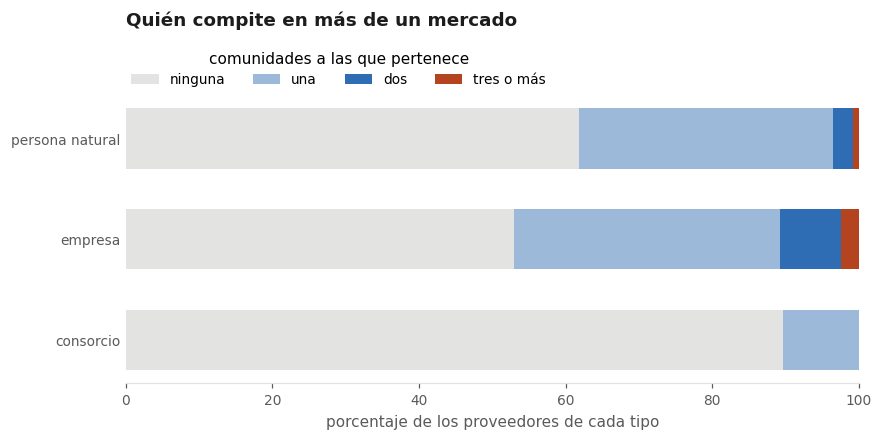

In [8]:
def correr_bigclam():
    t0 = time.perf_counter()
    Fm, hist = bigclam(A_ay, k_esp, iters=3000, paso=0.01, semilla=0, tol=0)
    return {"F": Fm, "historia": hist, "segundos": time.perf_counter() - t0}
with cronometro("BigCLAM sobre Ayacucho"):
    bc = guardado(f"bigclam_ayacucho_k{k_esp}", correr_bigclam)
Mem, delta = membresias_bigclam(bc["F"], A_ay)
n_com = Mem.sum(1)
duro = bc["F"].argmax(1)
print(f"umbral delta = {delta:.3f}; log verosimilitud final {bc['historia'][-1]['log_verosimilitud']:.0f} en {bc['segundos']:.0f} s")
solap = pd.DataFrame({"tipo": info_ay.tipo.values, "comunidades": np.minimum(n_com, 3)})
dist = (solap.groupby("tipo").comunidades.value_counts(normalize=True).unstack(fill_value=0) * 100).round(1)
dist.columns = ["ninguna" if c == 0 else ("una" if c == 1 else ("dos" if c == 2 else "tres o más")) for c in dist.columns]
print(dist)
pct_puente = 100 * (n_com >= 2).mean()
pct_periferia = 100 * (n_com == 0).mean()
grado_ay = np.asarray((A_ay > 0).sum(1)).ravel()
g_perif, g_resto = np.median(grado_ay[n_com == 0]), np.median(grado_ay[n_com > 0])
acuerdo_bc = {"ARI": ari(duro, etq_esp), "NMI": nmi(duro, etq_esp)}
print(f"{pct_puente:.0f} % de los proveedores de Ayacucho está en dos o más comunidades; "
      f"asignación dura de BigCLAM frente al espectral: ARI {acuerdo_bc['ARI']:.2f}, NMI {acuerdo_bc['NMI']:.2f}")
puentes = info_ay.assign(comunidades=n_com).query("comunidades >= 2").nlargest(10, "participaciones")[
    ["nombre", "tipo", "participaciones", "comunidades", "item_tipico"]]
print(puentes.to_string(index=False))
exportar(dist.reset_index(), "p5_bigclam_solapamiento", "Proveedores de Ayacucho segun en cuantas comunidades de BigCLAM estan")
exportar(puentes, "p5_bigclam_puentes", "Proveedores de Ayacucho con mas participaciones que estan en dos o mas comunidades")

fig, ax = plt.subplots(figsize=(8.6, 3.4))
cols = [c for c in ["ninguna", "una", "dos", "tres o más"] if c in dist.columns]
izq = np.zeros(len(dist))
for c, color in zip(cols, [REJILLA, "#9DB9DA", AZUL, ROJO]):
    ax.barh(dist.index, dist[c], left=izq, color=color, label=c, height=.6); izq += dist[c].values
ax.set_xlim(0, 100); ax.set_xlabel("porcentaje de los proveedores de cada tipo")
ax.legend(loc="lower left", bbox_to_anchor=(0, 1.01), ncols=4, borderaxespad=0, title="comunidades a las que pertenece")
ax.set_title("Quién compite en más de un mercado", loc="left", pad=46); ax.tick_params(axis="y", length=0)
ax.spines["left"].set_visible(False)
figura(fig, "f31_bigclam_solapamiento", f"""
BigCLAM separa tres situaciones que una partición mezcla. El {pct_periferia:.0f} por ciento de los proveedores de Ayacucho
no tiene afiliación fuerte con ninguna comunidad: es la periferia, con un grado mediano de {g_perif:.0f} rivales frente a
{g_resto:.0f} del resto. La mayoría pertenece a una sola. Y el {pct_puente:.0f} por ciento está en dos o más a la vez: son los
proveedores puente, casi todos empresas, que compiten en varios mercados; la tabla de arriba muestra los más
activos. Su asignación dura se parece poco al espectral (NMI de {acuerdo_bc['NMI']:.2f}) porque modela otra cosa: no
reparte a todos, describe núcleos que se solapan. Para un supervisor, el puente es quien puede llevar competencia de
un submercado a otro.""")

## 8. Las comunidades de Ayacucho y las señales de las partes anteriores

Con la partición de Louvain sobre Ayacucho, que es la de mayor Q, se describe cada comunidad grande: cuántos proveedores tiene, qué rubro domina, cuánto ganó y cuántos pares afines y pares que alternan victorias de la Parte IV viven dentro. La pregunta de supervisión es si esas señales están dispersas o concentradas en pocos mercados.

 comunidad  proveedores                                    item_tipico  pct_familia  pct_personas_naturales  monto_ganado  pares_afines  pares_que_alternan
        17          276 SERVICIO DE MANTENIMIENTO RUTINARIO DE CAMINOS           59                      17  149316394.87            12                   0
         9          191 SERVICIO DE MANTENIMIENTO RUTINARIO DE CAMINOS           98                      19   47065066.55           200                   9
         6          165 SERVICIO DE MANTENIMIENTO RUTINARIO DE CAMINOS           53                      22  119188891.71            13                   1
        19           82 SERVICIO DE MANTENIMIENTO DE INFRAESTRUCTURA D           41                      11  169882835.57             2                   0
         4           74                          ARROZ PILADO SUPERIOR           36                      22   80422341.54            24                   3
         5           60 CEMENTO PORTLAND PUZOLANICO TIPO IP X 42


Lectura de f32_comunidades_ayacucho
Cada barra es un mercado de competencia de Ayacucho, con su rubro típico y el monto que ganaron sus proveedores. De los 317 pares afines de la Parte I que viven en Ayacucho, el 94 por ciento cae dentro de una misma comunidad, cuando dos proveedores al azar caerían juntos el 14 por ciento de las veces. Más aún, una sola comunidad, de 191 proveedores cuyo rubro típico es servicio de mantenimiento rutinario de caminos, reúne 200 de esos pares. Las señales de coordinación no están dispersas: se concentran en pocos mercados, y eso permite asignar la revisión por mercado y no proveedor por proveedor.



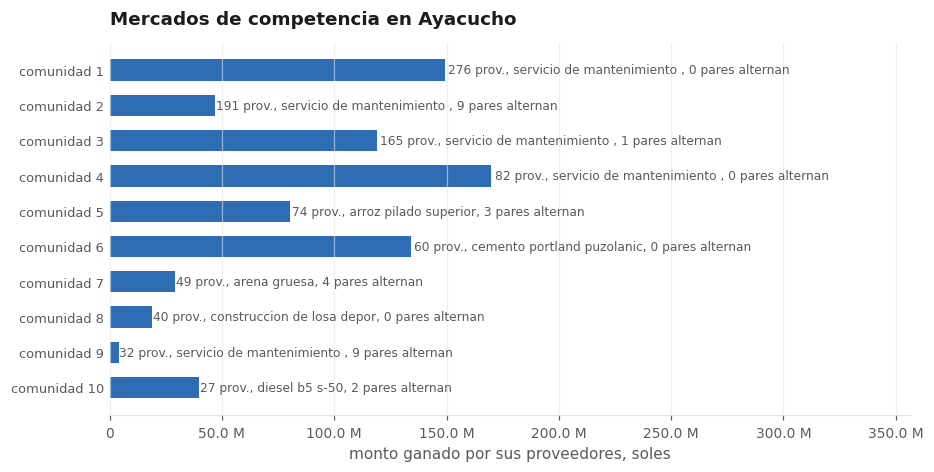

In [9]:
info_ay = info_ay.assign(comunidad=etq_louv)
pos = pd.Series(np.arange(len(idx_ay)), index=idx_ay)
p_ay = pares[pares.src.isin(idx_ay) & pares.dst.isin(idx_ay)].copy()
p_ay["misma"] = etq_louv[pos[p_ay.src].values] == etq_louv[pos[p_ay.dst].values]
tam_ay = pd.Series(etq_louv).value_counts()
esperado = 100 * ((tam_ay / tam_ay.sum()) ** 2).sum()
filas = []
for c in tam_ay.index[:10]:
    m = info_ay[info_ay.comunidad == c]
    fam = m.familia.value_counts(normalize=True)
    pc = p_ay[p_ay.misma & (etq_louv[pos[p_ay.src].values] == c)]
    filas.append({"comunidad": int(c), "proveedores": len(m),
                  "item_tipico": str(item_tipico.get(fam.index[0], ""))[:46] if len(fam) else "",
                  "pct_familia": round(100 * fam.iloc[0]) if len(fam) else 0,
                  "pct_personas_naturales": round(100 * (m.tipo == "persona natural").mean()),
                  "monto_ganado": m.monto_total.sum(), "pares_afines": len(pc),
                  "pares_que_alternan": int((pc.patron == "alternan").sum())})
com_ay = pd.DataFrame(filas)
print(com_ay.to_string(index=False))
alt = p_ay[p_ay.patron == "alternan"]
pct_alt_misma = 100 * alt.misma.mean() if len(alt) else np.nan
print(f"Pares afines en Ayacucho: {len(p_ay)}; dentro de una misma comunidad: {100*p_ay.misma.mean():.0f} %. "
      f"Pares que alternan: {len(alt)}, {pct_alt_misma:.0f} % dentro de una misma comunidad; "
      f"dos proveedores al azar caerían juntos el {esperado:.0f} % de las veces")
exportar(com_ay, "p5_comunidades_ayacucho", "Perfil de las 10 comunidades mas grandes de Ayacucho")
c0 = com_ay.loc[com_ay.pares_afines.idxmax()]

fig, ax = plt.subplots(figsize=(9.4, 4.4))
y = np.arange(len(com_ay))[::-1]
ax.barh(y, com_ay.monto_ganado, color=AZUL, height=.6)
for yi, r in zip(y, com_ay.itertuples()):
    ax.text(r.monto_ganado * 1.01, yi, f"{r.proveedores} prov., {r.item_tipico[:26].lower()}, {r.pares_que_alternan} pares alternan",
            va="center", fontsize=8, color=SUAVE)
ax.set_yticks(y, [f"comunidad {i+1}" for i in range(len(com_ay))], fontsize=8.5)
ax.xaxis.set_major_formatter(MILES); ax.set_xlim(0, com_ay.monto_ganado.max() * 2.1)
ax.set_xlabel("monto ganado por sus proveedores, soles"); ax.tick_params(axis="y", length=0)
ax.set_title("Mercados de competencia en Ayacucho", loc="left", pad=12)
ax.grid(axis="x", alpha=.6); ax.spines["left"].set_visible(False)
figura(fig, "f32_comunidades_ayacucho", f"""
Cada barra es un mercado de competencia de Ayacucho, con su rubro típico y el monto que ganaron sus proveedores.
De los {len(p_ay)} pares afines de la Parte I que viven en Ayacucho, el {100*p_ay.misma.mean():.0f} por ciento cae
dentro de una misma comunidad, cuando dos proveedores al azar caerían juntos el {esperado:.0f} por ciento de las
veces. Más aún, una sola comunidad, de {c0.proveedores} proveedores cuyo rubro típico es {c0.item_tipico.lower()}, reúne
{c0.pares_afines} de esos pares. Las señales de coordinación no están dispersas: se concentran en pocos mercados, y eso
permite asignar la revisión por mercado y no proveedor por proveedor.""")

## 9. Escalabilidad: qué se gana y qué se pierde

Se juntan los tiempos medidos. Girvan-Newman se extrapola con la pendiente ajustada en la sección 2; el resto se midió directamente.

                         metodo  nodos  aristas  segundos
                  Girvan-Newman     37      348      1.62
                  Girvan-Newman     67      941     19.22
                  Girvan-Newman     96     1617    106.44
                  Girvan-Newman    123     2203    194.60
                      espectral   1065     9650      0.14
                        Louvain   1065     9650      0.24
                        BigCLAM   1065     9650      5.94
propagación de etiquetas, Spark  70383  2498491     70.81
        Louvain nacional, local  70383  2498491     65.28
Girvan-Newman extrapolado al grafo nacional: 1,482,411 años



Lectura de f33_escalabilidad_comunidades
El tiempo de Girvan-Newman crece como el número de proveedores elevado a 4.1: con 123 proveedores ya tarda 195 segundos, y sobre los 70,383 del grafo nacional tardaría del orden de 1,482,411 años. La propagación de etiquetas en Spark procesa ese grafo completo en 71 segundos, y Louvain en una sola máquina en 65, con más calidad pero con todo el grafo en memoria: esa es la frontera que Spark corre cuando el volumen crece. Lo que se pierde al escalar es la jerarquía completa de cortes y la garantía de explorar cada partición; lo que se gana es poder mirar el país entero. Por eso el diseño combina los dos: el método exacto para entender un mercado y el escalable para mapearlos todos.



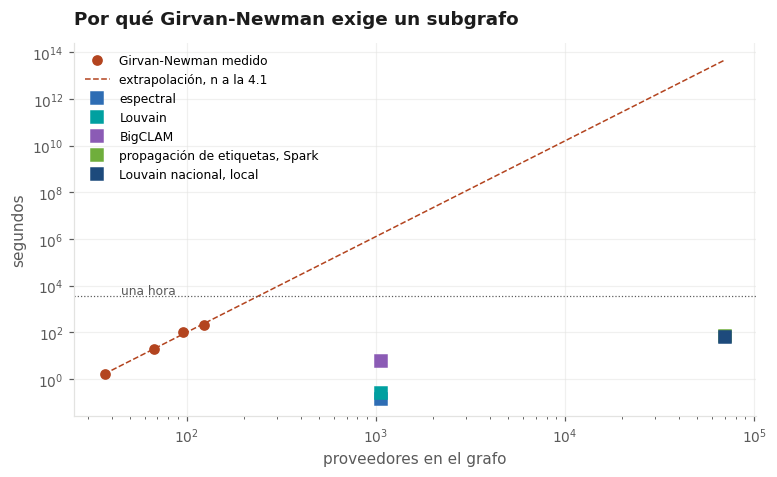

In [10]:
t_esp1 = time.perf_counter(); espectral(A_ay, k_esp); t_esp1 = time.perf_counter() - t_esp1
n_g1 = A_g1.shape[0]
gn_nacional = np.exp(np.polyval(pend, np.log(n_g1)))
esc = pd.concat([escala, pd.DataFrame([
    {"metodo": "espectral", "nodos": A_ay.shape[0], "aristas": A_ay.nnz // 2, "segundos": t_esp1},
    {"metodo": "Louvain", "nodos": A_ay.shape[0], "aristas": A_ay.nnz // 2, "segundos": t_louv},
    {"metodo": "BigCLAM", "nodos": A_ay.shape[0], "aristas": A_ay.nnz // 2, "segundos": bc["segundos"]},
    {"metodo": "propagación de etiquetas, Spark", "nodos": n_g1, "aristas": A_g1.nnz // 2, "segundos": lpa["segundos"]},
    {"metodo": "Louvain nacional, local", "nodos": n_g1, "aristas": A_g1.nnz // 2, "segundos": lv_nac["segundos"]}])],
    ignore_index=True)
print(esc.round(2).to_string(index=False))
print(f"Girvan-Newman extrapolado al grafo nacional: {gn_nacional/3600/24/365:,.0f} años")
exportar(esc.round(3), "p5_escalabilidad", "Tiempo de cada metodo de comunidades segun el tamano del grafo")

fig, ax = plt.subplots(figsize=(8, 4.4))
g = esc[esc.metodo == "Girvan-Newman"]
xs = np.logspace(np.log10(40), np.log10(n_g1), 50)
ax.loglog(g.nodos, g.segundos, "o", color=ROJO, label="Girvan-Newman medido")
ax.loglog(xs, np.exp(np.polyval(pend, np.log(xs))), "--", color=ROJO, lw=1, label=f"extrapolación, n a la {pend[0]:.1f}")
for (m, c) in [("espectral", AZUL), ("Louvain", TEAL), ("BigCLAM", MORADO), ("propagación de etiquetas, Spark", VERDE),
               ("Louvain nacional, local", "#1D4A7C")]:
    r = esc[esc.metodo == m].iloc[0]
    ax.loglog([r.nodos], [r.segundos], "s", color=c, ms=8, label=m)
ax.axhline(3600, color=SUAVE, lw=.8, ls=":"); ax.text(45, 4300, "una hora", fontsize=8, color=SUAVE)
ax.set_xlabel("proveedores en el grafo"); ax.set_ylabel("segundos")
ax.set_title("Por qué Girvan-Newman exige un subgrafo", loc="left", pad=12)
ax.legend(fontsize=8, loc="upper left"); ax.grid(alpha=.5)
figura(fig, "f33_escalabilidad_comunidades", f"""
El tiempo de Girvan-Newman crece como el número de proveedores elevado a {pend[0]:.1f}: con {g.nodos.iloc[-1]} proveedores ya tarda
{g.segundos.iloc[-1]:.0f} segundos, y sobre los {n_g1:,} del grafo nacional tardaría del orden de
{gn_nacional/3600/24/365:,.0f} años. La propagación de etiquetas en Spark procesa ese grafo completo en
{lpa['segundos']:.0f} segundos, y Louvain en una sola máquina en {lv_nac['segundos']:.0f}, con más calidad pero con todo el grafo
en memoria: esa es la frontera que Spark corre cuando el volumen crece. Lo que se pierde al escalar es la
jerarquía completa de cortes y la garantía de explorar cada partición; lo que se gana es poder mirar el país
entero. Por eso el diseño combina los dos: el método exacto para entender un mercado y el escalable para
mapearlos todos.""")

## 10. Hallazgos de la Parte V

In [11]:
hallazgo("V", "Se compite en la región, pero los mercados son de rubro",
         f"""El {pct_peso_mismo:.0f} por ciento del peso del grafo de coparticipación une a proveedores del mismo
         departamento, y aun así las comunidades nacionales se explican por el rubro (NMI {nd.loc['Louvain nacional frente a familia CUBSO','NMI']:.2f}
         con la familia CUBSO) y no por el departamento (NMI {nd.loc['Louvain nacional frente a departamento','NMI']:.2f}). Los
         mercados de servicios, como el mantenimiento de caminos y la supervisión de obra, son nacionales; los de bienes
         pesados, como el cemento, son regionales.""",
         """Definir los mercados para medir concentración y competencia a partir de las comunidades y no por
         departamento ni por familia sueltos: un rubro de servicios se mide a escala nacional y uno de bienes pesados,
         por región.""",
         "f30_comunidades_nacionales, p5_comunidades_nacionales, p5_acuerdo")
hallazgo("V", "Dentro de una región, los mercados se parecen al rubro y concentran las señales",
         f"""En Ayacucho, Girvan-Newman, espectral y Louvain reconocen la misma estructura (NMI entre
         {a.loc['espectral frente a Louvain, Ayacucho','NMI']:.2f} y {a.loc['Girvan-Newman frente a espectral, núcleo','NMI']:.2f})
         con Q de hasta {q_louv:.2f}. Las comunidades se parecen al rubro y no al perfil de comportamiento de la
         Parte II. El {100*p_ay.misma.mean():.0f} por ciento de los pares afines cae dentro de una misma comunidad,
         frente al {esperado:.0f} por ciento esperable al azar.""",
         """Asignar la revisión de pares afines y que alternan por mercado de competencia: cada comunidad con
         varias señales es un caso de mercado, no una lista de proveedores sueltos.""",
         "f32_comunidades_ayacucho, f29_acuerdo_particiones, p5_comunidades_ayacucho")
hallazgo("V", "Los métodos exactos sirven para entender un mercado; los escalables, para mapear el país",
         f"""Girvan-Newman crece como n elevado a {pend[0]:.1f} y sobre el grafo nacional tardaría del orden de
         {gn_nacional/3600/24/365:,.0f} años; la
         propagación de etiquetas en Spark lo resuelve en {lpa['segundos']:.0f} segundos y reencuentra la estructura de
         Louvain (NMI {nd.loc['propagación frente a Louvain, nacional','NMI']:.2f}), aunque con menor modularidad
         ({q_lpa:.2f} frente a {q_lvn:.2f}). BigCLAM agrega lo que
         ninguna partición da: el {pct_puente:.0f} por ciento de los proveedores de Ayacucho compite en dos o más
         mercados a la vez.""",
         """Usar el método escalable para mantener un mapa nacional de mercados actualizado cada trimestre, y
         los métodos exactos y BigCLAM para estudiar a fondo los mercados que ese mapa marque.""",
         "f33_escalabilidad_comunidades, f31_bigclam_solapamiento, p5_escalabilidad")


HALLAZGO. Se compite en la región, pero los mercados son de rubro
El 60 por ciento del peso del grafo de coparticipación une a proveedores del mismo departamento, y aun así las comunidades nacionales se explican por el rubro (NMI 0.48 con la familia CUBSO) y no por el departamento (NMI 0.14). Los mercados de servicios, como el mantenimiento de caminos y la supervisión de obra, son nacionales; los de bienes pesados, como el cemento, son regionales.
Accion propuesta: Definir los mercados para medir concentración y competencia a partir de las comunidades y no por departamento ni por familia sueltos: un rubro de servicios se mide a escala nacional y uno de bienes pesados, por región.


HALLAZGO. Dentro de una región, los mercados se parecen al rubro y concentran las señales
En Ayacucho, Girvan-Newman, espectral y Louvain reconocen la misma estructura (NMI entre 0.47 y 0.91) con Q de hasta 0.64. Las comunidades se parecen al rubro y no al perfil de comportamiento de la Parte II. El 94 por 

In [12]:
# Para el reporte: el núcleo de Girvan-Newman con su partición en cada nivel, para que el
# navegador recolore el grafo al mover el número de comunidades.
niveles = curva_gn[curva_gn.k <= 30].k.tolist()
nucleo = nod.set_index("nodo").reindex(idx_ay[sel_gn])[["nombre", "tipo", "item_tipico"]].reset_index()
for h in hist_gn:
    if h["k"] in niveles:
        nucleo[f"k{h['k']}"] = h["etiquetas"]
T = sparse.triu(A_gn, 1).tocoo()
exportar(nucleo, "p5_gn_nodos", "Nucleo de Ayacucho con la comunidad de Girvan-Newman en cada nivel")
exportar(pd.DataFrame({"i": T.row, "j": T.col, "peso": T.data.round(4)}), "p5_gn_aristas", "Aristas del nucleo de Ayacucho")
exportar(pd.DataFrame([{"q_girvan_newman": round(q_gn, 3), "k_girvan_newman": k_gn, "q_espectral": round(q_esp, 3),
                        "k_espectral": k_esp, "q_louvain": round(q_louv, 3), "k_louvain": len(louv),
                        "q_lpa": round(q_lpa, 3), "comunidades_lpa": len(tam), "q_louvain_nacional": round(q_lvn, 3),
                        "comunidades_louvain_nacional": int(len(np.unique(etq_lvn))), "pct_periferia": round(pct_periferia, 1), "segundos_lpa": round(lpa["segundos"], 1),
                        "pct_peso_mismo_departamento": round(pct_peso_mismo, 1), "pct_puente": round(pct_puente, 1),
                        "pct_afines_misma_comunidad": round(100 * p_ay.misma.mean(), 1), "pct_esperado": round(esperado, 1),
                        "exponente_gn": round(pend[0], 2), "proveedores_ayacucho": A_ay.shape[0]}]),
         "p5_resumen", "Cifras clave de la Parte V")
exportar(pd.DataFrame(FIGURAS), "p5_figuras", "Figuras de la Parte V con su lectura")
exportar(pd.DataFrame(HALLAZGOS), "p5_hallazgos", "Hallazgos de la Parte V con su accion propuesta")
nod[["nodo", "comunidad", "comunidad_louvain", "departamento", "familia"]].to_parquet(CACHE / "comunidades_nacionales.parquet")

**Cierre.** La segunda mitad de la pregunta 3 tiene respuesta: sí hay grupos de proveedores que compiten entre sí mucho más que con el resto, y no son arbitrarios. A escala nacional son mercados de rubro, aunque cada competencia ocurra dentro de una región; dentro de una región se parecen al rubro sin ser el rubro; y no tienen relación con el perfil de comportamiento de cada proveedor, que es otra dimensión. Las señales de la Parte IV, los pares afines y los que alternan, se concentran dentro de esos mercados.

**Decisiones que conviene recordar.** El número de comunidades se eligió por el codo de la modularidad y no por su máximo. Los métodos se compararon entre sí con ARI y NMI, no solo con Q. Girvan-Newman se limitó a 150 proveedores con una medición de su costo, y el grafo nacional se resolvió con propagación de etiquetas en Spark.

**Encuadre ético.** Una comunidad es un grupo de proveedores que coinciden en los mismos procesos. Coincidir es lo normal en un mercado regional con pocos oferentes y no implica acuerdo alguno. Lo que esta parte aporta es el contexto para leer las señales: un par que alterna victorias dentro de un mercado de seis proveedores no se interpreta igual que uno dentro de un mercado de doscientos.

In [13]:
spark.stop()